## Deploy the vector DB on your own, and implement the `vector cosine similarity` without using a high level library. 

for the vector DB, I'm using qdrant vector DB, simply because qdrant is my most familiar vector database.

for the deployment of qdrant, I make it simple with using docker compose, you can find here: [docker compose](docker-compose.yml)

the qdrant DB, will be served at 127.0.0.1:6333:6333, or localhost:6333 

after running the docker compose, kindly check this url on your localhost: http://localhost:6333/dashboard#/welcome to validate if the qdrant db is running

### Check qdrant uptime and collection

In [67]:
from qdrant_client import QdrantClient, models

client = QdrantClient(url="http://localhost:6333")

collections = client.get_collections()
print(collections)


collections=[CollectionDescription(name='cosine-similarity-test')]


In [68]:
collection_name = "cosine-similarity-test"
info = client.get_collection(collection_name)

info

CollectionInfo(status=<CollectionStatus.GREEN: 'green'>, optimizer_status=<OptimizersStatusOneOf.OK: 'ok'>, warnings=None, indexed_vectors_count=0, points_count=4, segments_count=8, config=CollectionConfig(params=CollectionParams(vectors={'': VectorParams(size=4, distance=<Distance.COSINE: 'Cosine'>, hnsw_config=HnswConfigDiff(m=24, ef_construct=256, full_scan_threshold=None, max_indexing_threads=None, on_disk=None, memory=None, payload_m=24, inline_storage=None), quantization_config=None, on_disk=False, memory=None, datatype=<Datatype.FLOAT32: 'float32'>, multivector_config=None)}, shard_number=1, sharding_method=None, replication_factor=1, write_consistency_factor=1, read_fan_out_factor=None, read_fan_out_delay_ms=None, on_disk_payload=True, payload=None, sparse_vectors=None), hnsw_config=HnswConfig(m=16, ef_construct=100, full_scan_threshold=10000, max_indexing_threads=0, on_disk=False, memory=None, payload_m=None, inline_storage=None), optimizer_config=OptimizersConfig(deleted_thre

### Create dummy data points and insert to qdrant

In [69]:
dummy_points = [
    models.PointStruct(
        id=1,
        vector=[0.9, 0.1, 0.2, 0.0],
        payload={
            "text": "Python is a programming language",
            "category": "technology"
        }
    ),
    models.PointStruct(
        id=2,
        vector=[0.8, 0.2, 0.3, 0.1],
        payload={
            "text": "Machine learning learns from data",
            "category": "AI"
        }
    ),
    models.PointStruct(
        id=3,
        vector=[0.0, 0.1, 0.9, 0.8],
        payload={
            "text": "Football is a popular sport",
            "category": "sports"
        }
    )
]

here, if we running the code again, and the data already exist:
Qdrant behavior:
- New ID + different text: A new point is inserted
- Existing ID + different text: The existing point is overwritten, not duplicated
- Existing ID + identical text: The existing point is overwritten as well
- New ID + identical text: A new point is inserted, potentially creating duplicate text

In [70]:
try:
    collection_name = "cosine-similarity-test"
    info = client.get_collection(collection_name)

    client.upsert(
        collection_name=collection_name,
        points=dummy_points,
        wait=True
    )
    print("Successfully insert data.")

except Exception as e:
    print(f"Error: {e}")

Successfully insert data.


### Validate the data already exist

In [71]:
collection_name = "cosine-similarity-test"

# Check collection info
info = client.get_collection(collection_name)
print("Total points:", info.points_count)

# Retrieve stored data
points, _ = client.scroll(
    collection_name=collection_name,
    limit=100,
    with_payload=True,
    with_vectors=True
)

for point in points:
    print(f"\nID: {point.id}")
    print(f"Payload: {point.payload}")
    print(f"Vector: {point.vector}")

Total points: 4

ID: 1
Payload: {'text': 'Python is a programming language', 'category': 'technology'}
Vector: [0.9704949, 0.107832775, 0.21566555, 0.0]

ID: 2
Payload: {'text': 'Machine learning learns from data', 'category': 'AI'}
Vector: [0.90582156, 0.22645539, 0.3396831, 0.113227695]

ID: 3
Payload: {'text': 'Football is a popular sport', 'category': 'sports'}
Vector: [0.0, 0.08276059, 0.7448453, 0.6620847]

ID: 4
Payload: {'text': 'Python is a programming language for AI', 'category': 'technology'}
Vector: [0.9233805, 0.10259784, 0.20519568, 0.30779353]


### Calculate the cosine similarity

cosine similarity equation:


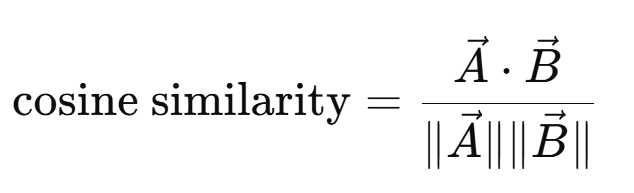

In [72]:
from IPython.display import Image, display
print(f"cosine similarity equation:")
display(Image(filename="assets/cosine_similarity.png"))

In [73]:
import numpy as np

def calculate_cosine_similarity(vector_a, vector_b):
    vector_a = np.array(vector_a)
    vector_b = np.array(vector_b)

    denominator = np.linalg.norm(vector_a) * np.linalg.norm(vector_b)

    if denominator == 0:
        return 0.0
    
    return float(np.dot(vector_a, vector_b) / denominator)

# validate the equation
score = calculate_cosine_similarity(
     [0.0, 0.1, 0.9, 0.8],
     [0.0, 0.1, 0.9, 0.8],
)
print(f"Cosine similarity: {score:.4f}")

Cosine similarity: 1.0000


### Similarity Search

In [74]:
def similarity_search(query_vector, top_k):
    points, _ = client.scroll(
        collection_name="cosine-similarity-test",
        limit=100,
        with_vectors=True
    )

    results = [
        {
            "id": point.id,
            "text": point.payload["text"],
            "score": calculate_cosine_similarity(
                query_vector, point.vector
            )
        }
        for point in points
    ]

    return sorted(
        results,
        key=lambda x: x["score"],
        reverse=True
    )[:top_k]

query_vector = [0.9233805, 0.10259784, 0.20519568, 0.30779353]

results = similarity_search(query_vector, top_k=3)

for result in results:
    print(result)

{'id': 4, 'text': 'Python is a programming language for AI', 'score': 1.0}
{'id': 2, 'text': 'Machine learning learns from data', 'score': 0.9642041276442337}
{'id': 1, 'text': 'Python is a programming language', 'score': 0.9514531737424997}
